# 20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.615188,0.043392,15
1,DAGMA_Linear,0.244411,0.096911,15
2,DAGMA_Nonlinear,0.335257,0.058819,15
3,DAS,0.405120,0.074142,15
4,DirectLiNGAM,0.351732,0.063968,15
5,FCI,0.219233,0.117168,15
6,GES,0.485273,0.090578,15
7,GOLEM,0.230780,0.083236,15
8,GRaSP,0.472341,0.095617,15
9,GraNDAG,0.143401,0.154354,15


,model,mean,std,size
0,AVICI,17.933333,4.558613,15
1,DAGMA_Linear,25.466667,4.356713,15
2,DAGMA_Nonlinear,25.164444,3.706011,15
3,DAS,34.800000,6.504943,15
4,DirectLiNGAM,36.000000,10.555973,15
5,FCI,32.960000,6.478183,15
6,GES,27.933333,5.496319,15
7,GOLEM,29.933333,5.311264,15
8,GRaSP,24.186667,4.324768,15
9,GraNDAG,25.133333,3.398879,15


,model,mean,std,size
0,AVICI,0.668837,0.093910,15
1,DAGMA_Linear,0.357443,0.148350,15
2,DAGMA_Nonlinear,0.410465,0.069238,15
3,DAS,0.331030,0.072002,15
4,DirectLiNGAM,0.292690,0.064904,15
5,FCI,0.576763,0.266498,15
6,GES,0.466299,0.084873,15
7,GOLEM,0.284426,0.104228,15
8,GRaSP,0.576078,0.090848,15
9,GraNDAG,0.492650,0.363609,15


,model,mean,std,size
0,AVICI,0.583620,0.077072,15
1,DAGMA_Linear,0.191336,0.083537,15
2,DAGMA_Nonlinear,0.290159,0.062664,15
3,DAS,0.529117,0.090282,15
4,DirectLiNGAM,0.454457,0.095456,15
5,FCI,0.138177,0.079096,15
6,GES,0.518986,0.128148,15
7,GOLEM,0.201896,0.080234,15
8,GRaSP,0.413810,0.112337,15
9,GraNDAG,0.088358,0.104034,15


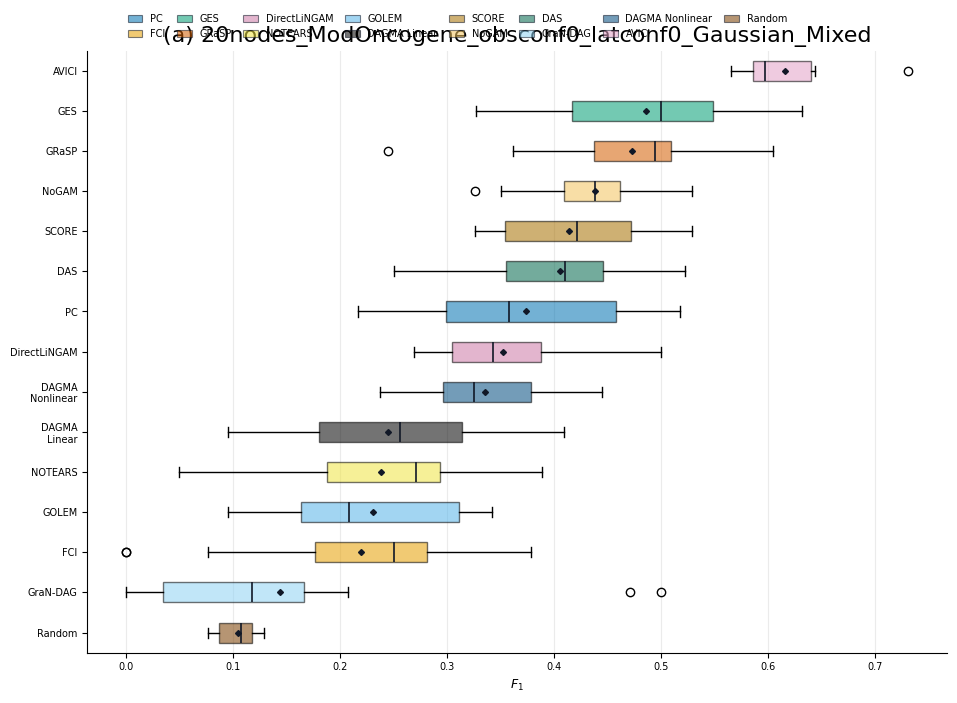

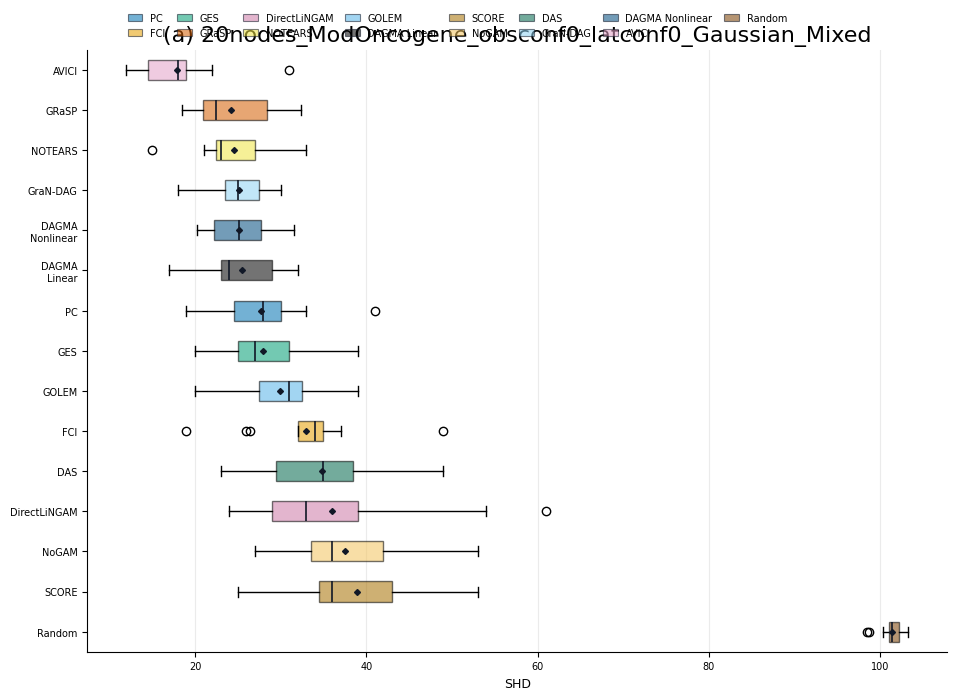

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.346952
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.000000
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.089575
9,13,GraNDAG,0.000000


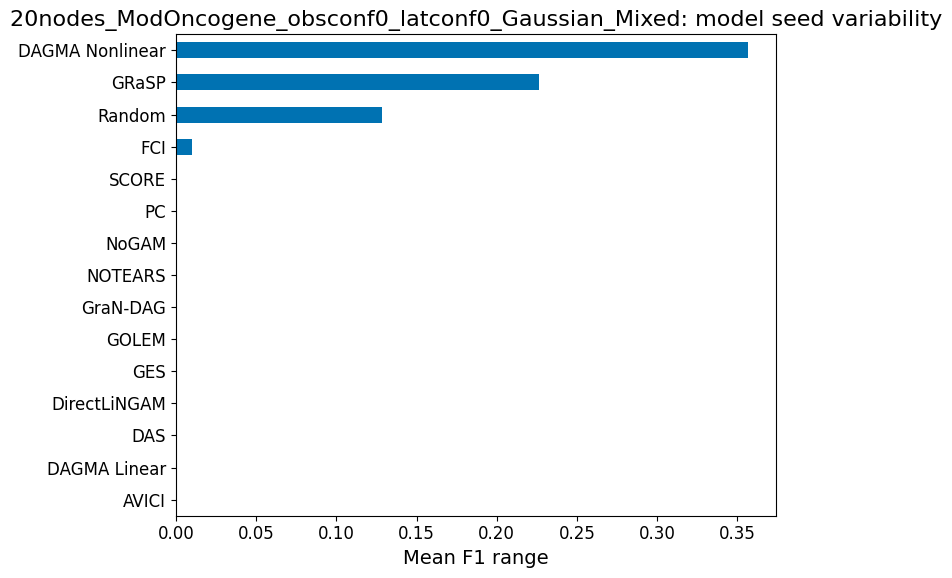

,model_seed,model,f1_range
0,0,AVICI,0.165552
1,0,DAGMA_Linear,0.313853
2,0,DAGMA_Nonlinear,0.400177
3,0,DAS,0.271739
4,0,DirectLiNGAM,0.230769
5,0,FCI,0.378378
6,0,GES,0.305048
7,0,GOLEM,0.246225
8,0,GRaSP,0.559307
9,0,GraNDAG,0.500000


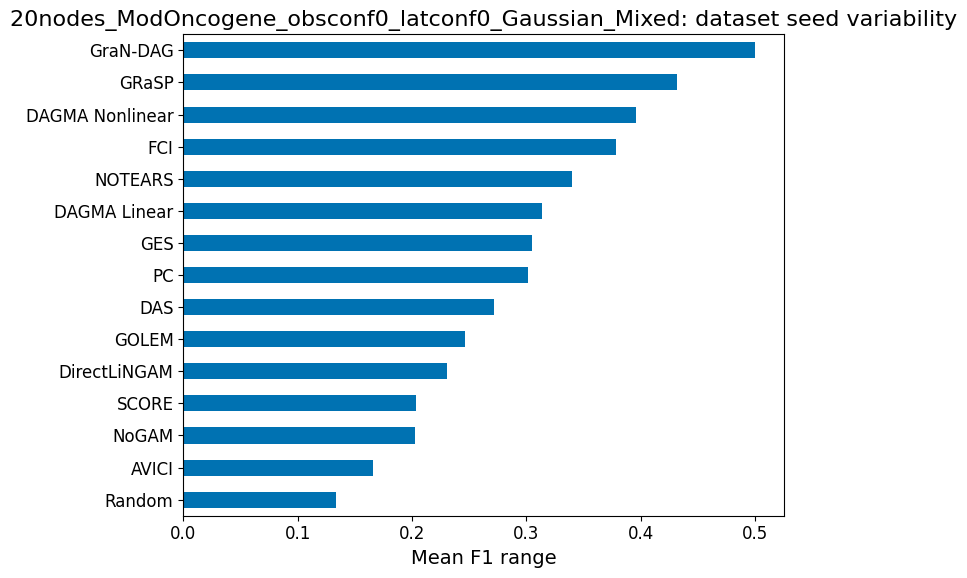

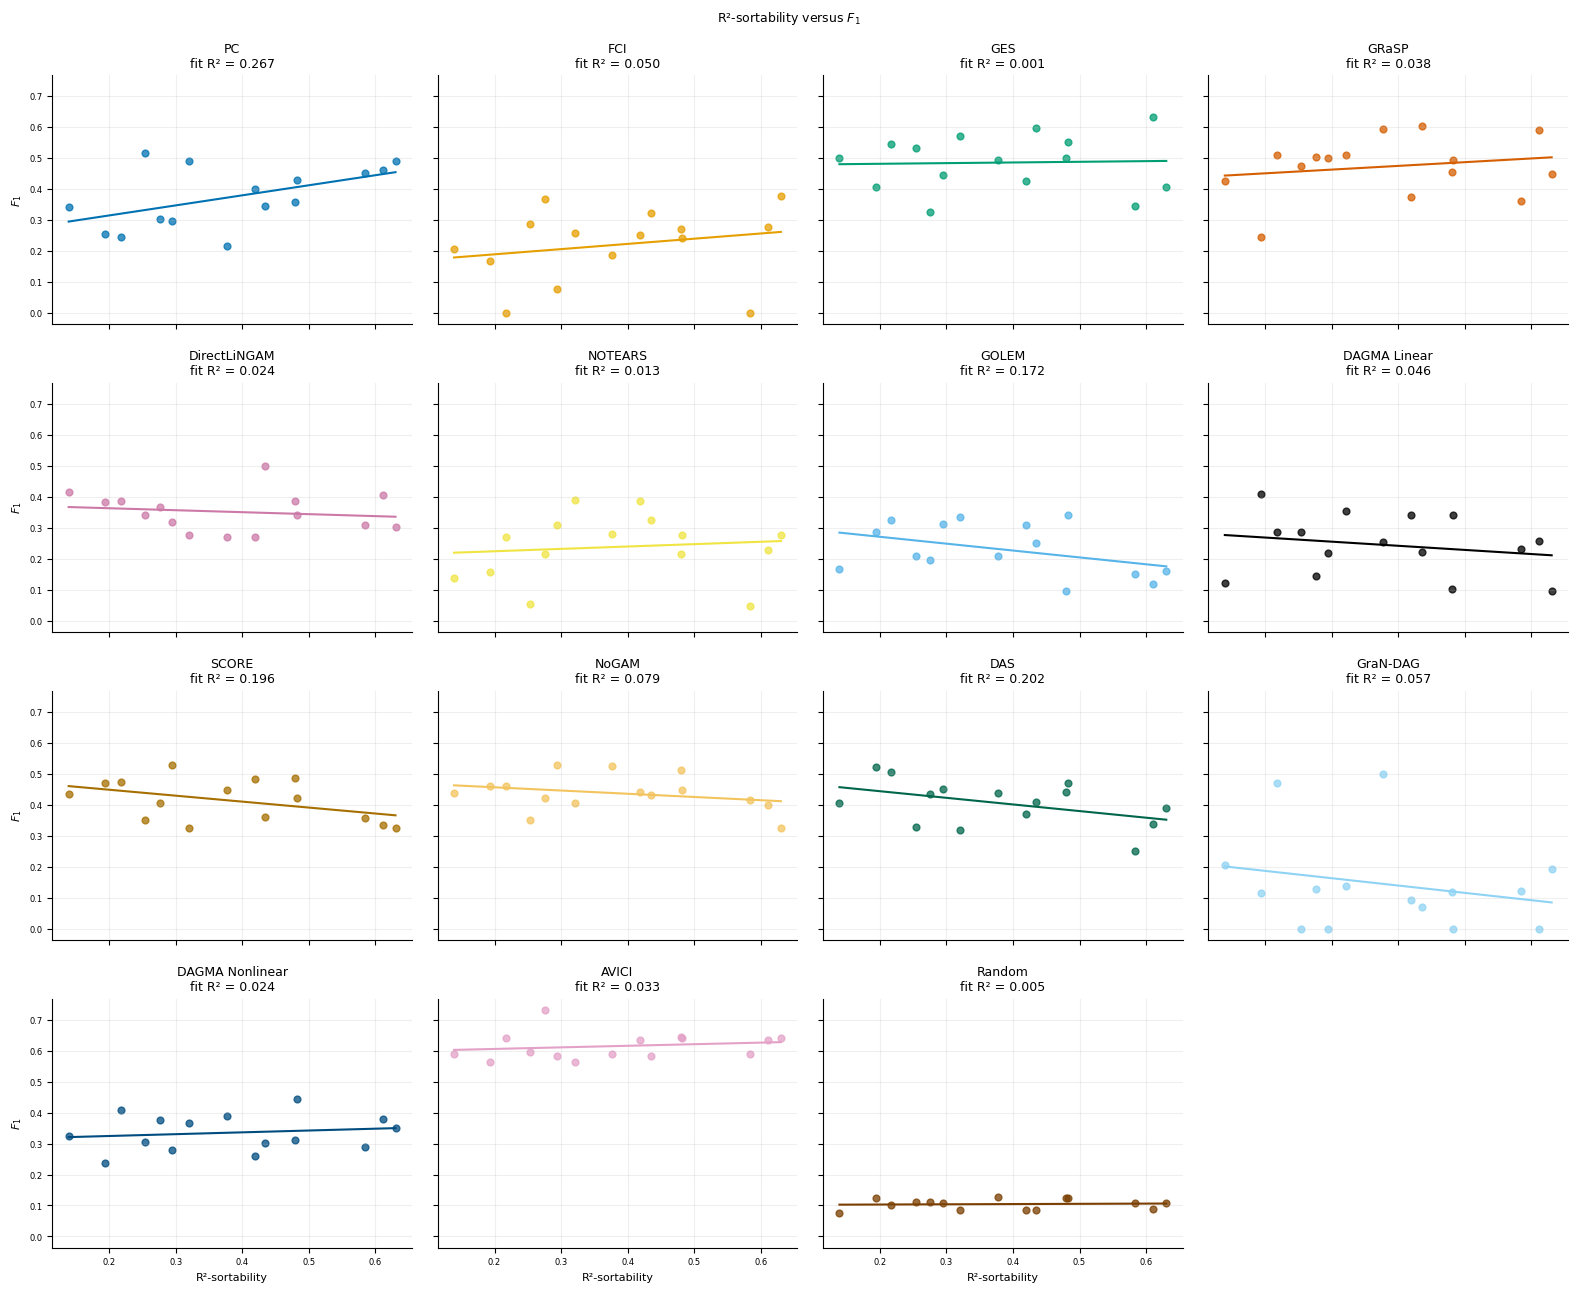

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,0.634146,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
1,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,0.342857,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
2,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,0.261393,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
3,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,0.370370,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
4,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,0.269231,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
5,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,FCI,0.250000,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
6,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GES,0.425532,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
7,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GOLEM,0.307692,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
8,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GRaSP,0.373048,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
9,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GraNDAG,0.090909,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,13,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
1,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,21,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.478261,0.376812,69,33,0,26,0,20,2000
2,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,29,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.490196,0.294118,51,25,0,15,0,20,2000
3,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,32,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.456522,0.630435,92,42,0,58,0,20,2000
4,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,44,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.533333,0.480000,75,40,0,36,0,20,2000
5,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,47,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.321739,0.139130,115,37,0,16,0,20,2000
6,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,52,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.500000,0.482143,56,28,0,27,0,20,2000
7,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,71,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.478261,0.217391,46,22,0,10,0,20,2000
8,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,75,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.391304,0.434783,92,36,0,40,0,20,2000
9,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,102,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.620690,0.275862,58,36,0,16,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.183020,0.033496,0.050993,0.595764,0.513828,0.237712,0.393597
1,DAGMA_Linear,15,-0.214141,0.045857,-0.133253,0.295169,0.443455,-0.237712,0.393597
2,DAGMA_Nonlinear,15,0.156283,0.024424,0.059024,0.312774,0.578069,0.153571,0.584764
3,DAS,15,-0.449557,0.202102,-0.214019,0.486642,0.092718,-0.346429,0.205896
4,DirectLiNGAM,15,-0.155227,0.024095,-0.063758,0.376018,0.580673,-0.232350,0.404667
5,FCI,15,0.223587,0.049991,0.168213,0.155159,0.423106,0.328865,0.231368
6,GES,15,0.036906,0.001362,0.021465,0.477097,0.896107,0.092857,0.742045
7,GOLEM,15,-0.415306,0.172479,-0.221963,0.315328,0.123696,-0.353888,0.195644
8,GRaSP,15,0.195583,0.038253,0.120079,0.426602,0.484823,0.089286,0.751673
9,GraNDAG,15,-0.239052,0.057146,-0.236925,0.233648,0.390857,-0.234244,0.400739


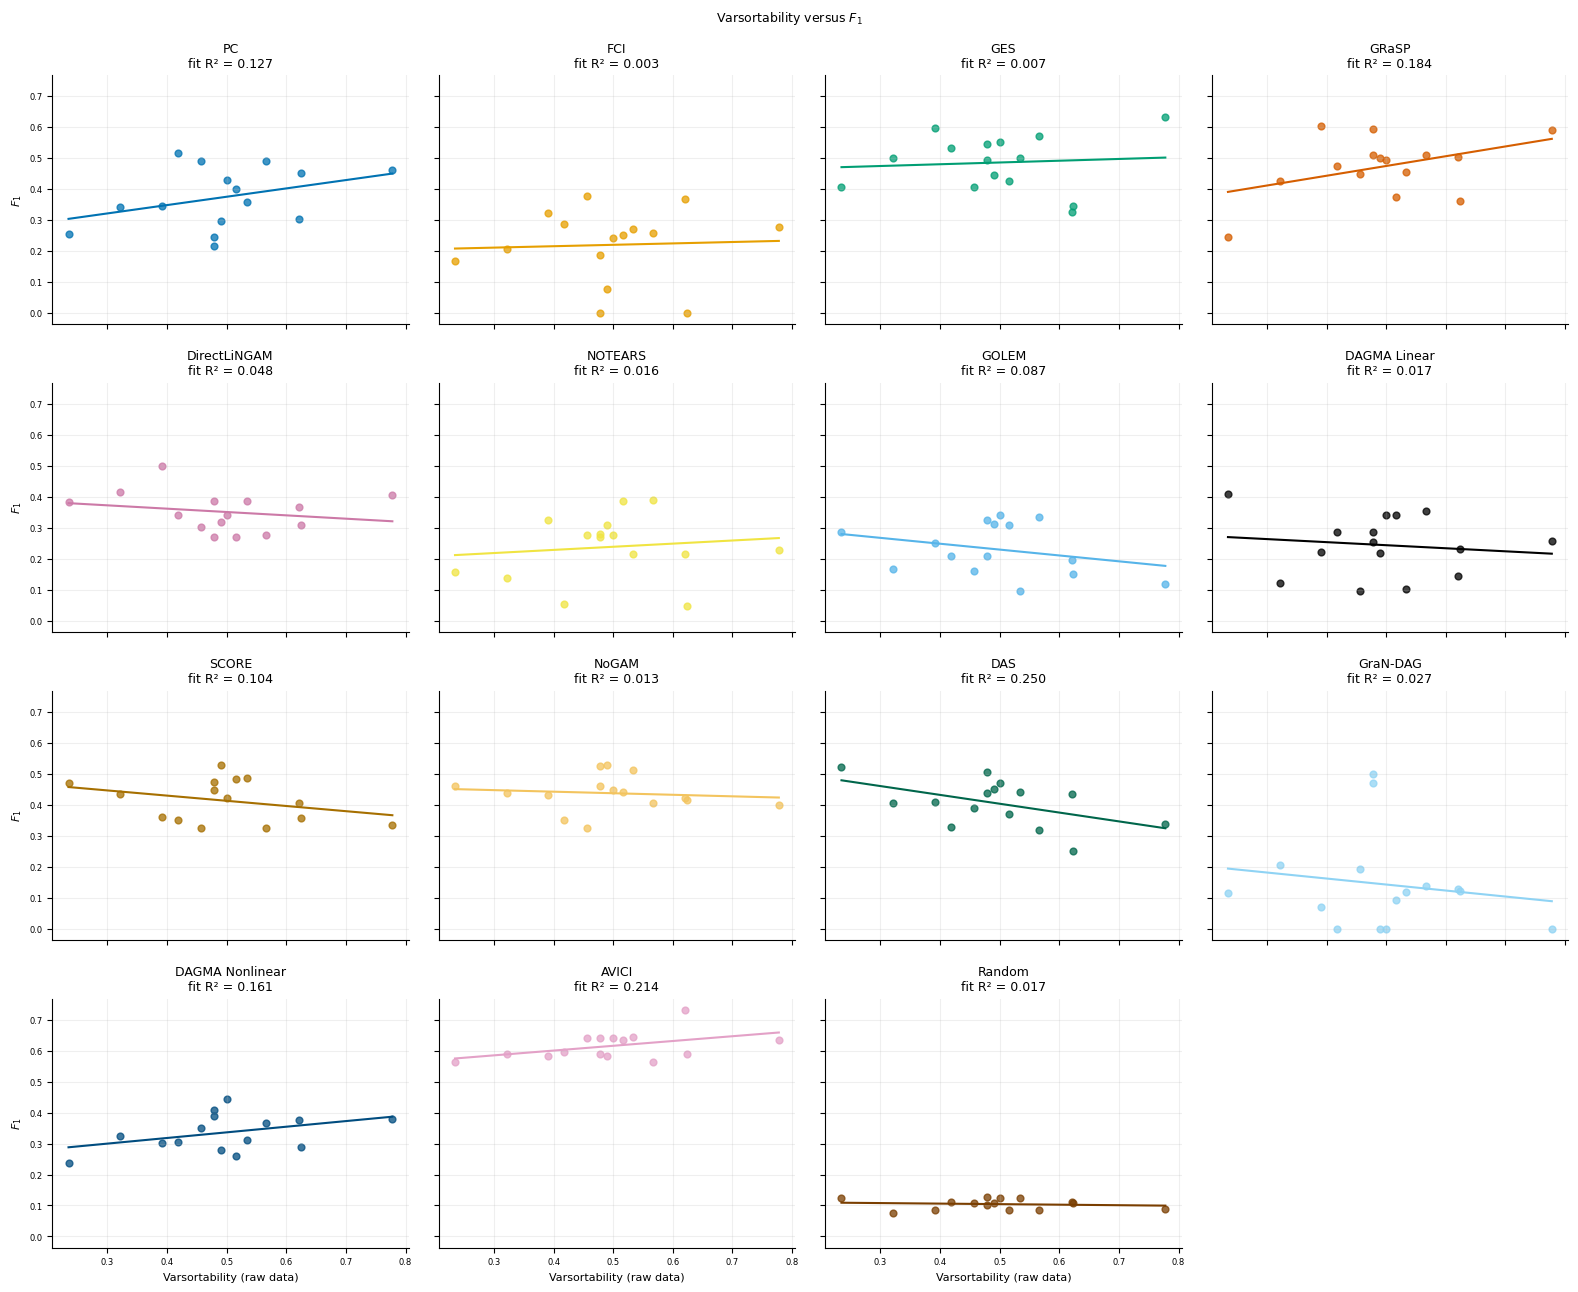

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,0.634146,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
1,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,0.342857,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
2,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,0.261393,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
3,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,0.370370,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
4,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,0.269231,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
5,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,FCI,0.250000,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
6,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GES,0.425532,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
7,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GOLEM,0.307692,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
8,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GRaSP,0.373048,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
9,13,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GraNDAG,0.090909,15,20,ModOncogene,0,0,Gaussian,...,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,13,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.516129,0.419355,31,16,0,13,0,20,2000
1,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,21,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.478261,0.376812,69,33,0,26,0,20,2000
2,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,29,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.490196,0.294118,51,25,0,15,0,20,2000
3,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,32,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.456522,0.630435,92,42,0,58,0,20,2000
4,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,44,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.533333,0.480000,75,40,0,36,0,20,2000
5,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,47,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.321739,0.139130,115,37,0,16,0,20,2000
6,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,52,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.500000,0.482143,56,28,0,27,0,20,2000
7,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,71,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.478261,0.217391,46,22,0,10,0,20,2000
8,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,75,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.391304,0.434783,92,36,0,40,0,20,2000
9,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,102,benchmark,True,datasets/benchmark/20nodes_ModOncogene_obsconf...,0.620690,0.275862,58,36,0,16,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.462401,0.213814,0.154590,0.538856,0.082659,0.338104,0.217736
1,DAGMA_Linear,15,-0.132218,0.017482,-0.098722,0.293158,0.638553,-0.002683,0.992427
2,DAGMA_Nonlinear,15,0.401672,0.161340,0.182028,0.245376,0.137795,0.255585,0.357884
3,DAS,15,-0.499705,0.249705,-0.285450,0.546068,0.057870,-0.393208,0.147073
4,DirectLiNGAM,15,-0.218845,0.047893,-0.107858,0.404990,0.433261,-0.256708,0.355703
5,FCI,15,0.050270,0.002527,0.045381,0.196825,0.858789,0.047406,0.866766
6,GES,15,0.081645,0.006666,0.056978,0.457139,0.772381,0.003575,0.989912
7,GOLEM,15,-0.295682,0.087428,-0.189622,0.324411,0.284627,-0.213775,0.444255
8,GRaSP,15,0.428523,0.183632,0.315691,0.316461,0.111005,0.146559,0.602222
9,GraNDAG,15,-0.163121,0.026608,-0.193990,0.239188,0.561328,-0.135261,0.630775


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,AVICI,r2_sortability,15,0.237712,0.393597,estimated,1.000000
1,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Linear,r2_sortability,15,-0.237712,0.393597,estimated,1.000000
2,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAGMA_Nonlinear,r2_sortability,15,0.153571,0.584764,estimated,1.000000
3,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DAS,r2_sortability,15,-0.346429,0.205896,estimated,1.000000
4,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,DirectLiNGAM,r2_sortability,15,-0.232350,0.404667,estimated,1.000000
5,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,FCI,r2_sortability,15,0.328865,0.231368,estimated,1.000000
6,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GES,r2_sortability,15,0.092857,0.742045,estimated,1.000000
7,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GOLEM,r2_sortability,15,-0.353888,0.195644,estimated,1.000000
8,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GRaSP,r2_sortability,15,0.089286,0.751673,estimated,1.000000
9,benchmark,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,GraNDAG,r2_sortability,15,-0.234244,0.400739,estimated,1.000000
